### CS771 Mini-Project 2, Problem 2
### Group members

| Name | Roll no. |
|:-----|:---------|
| Allala Srisharan Reddy | 250102 |
| Ponish Bhatia | 250781 |
| Rohan Rajeev Bharadwaj | 250911 |
| Saanvi Singh | 250934 |
| Sanath Koundinya | 250973 |

Executed top to bottom with fixed seeds; the PyTorch version and device are printed in the cell right after the data-generation cell.

# Is a language model secretly doing latent-variable inference?
### CS771 Mini-Project 2, Problem 2 — latent variable models, neural networks and LLMs in one toy world

Large language models are trained only to predict the next token. Yet they appear to "work out" what kind of text
they are looking at — a recipe, a proof, Python code — and adapt their predictions to it, without any change to their
weights. This is called **in-context learning**. In this lab you will build a tiny world in which you *know* the right
answer, and find out what a small transformer trained on next-token prediction is actually computing.

**The world.** Text over a vocabulary of $V=8$ tokens. Before writing a sequence, nature secretly picks a **concept**
$z\in\{1,\dots,4\}$; each concept is a Markov chain (see below) with its own transition matrix $\mathbf{A}_z$. The data are
therefore a **mixture of Markov chains** — a latent variable model, just like a GMM, but with discrete sequences as
observations.

**Plan** (about 3 hours of focused work; all heavy code is provided)

| part | what you do | time |
|---|---|---|
| 1 | Latent-variable inference: the posterior over the concept and the Bayes-optimal predictor | 30 min |
| 2 | Learn the mixture from unlabelled text with EM | 45 min |
| 3 | Train a tiny transformer; compare its loss with the best possible loss | 25 min |
| 4 | In-context learning as posterior inference | 20 min |
| 5 | Look inside: can the posterior be read off the hidden states? | 20 min |
| 6 | Limits: new concepts, and what changes with more diverse training data | 25 min |

---
### Background you need (a few ideas not covered in the lectures)

* **Markov chain.** A model of a token sequence in which the next token depends only on the *current* token, through a
  lookup table $\mathbf{A}$: $A[a,b] = p(x_{t+1}=b\mid x_t=a)$. Each row of $\mathbf{A}$ is a probability distribution over the $V$
  tokens (a multinoulli). The probability of a whole sequence is a product of table entries:
  $p(x_1,\dots,x_T) = p(x_1)\prod_{t=2}^{T}A[x_{t-1},x_t]$. It is the simplest possible "language model": a bigram model.
* **Entropy** of a distribution $p$ over $K$ outcomes: $H(p) = -\sum_k p_k\log p_k$. It is $0$ when $p$ is certain (one-hot) and
  $\log K$ when $p$ is uniform. Cross-entropy (Lectures 7, 19) is its two-distribution cousin.
* **Perplexity** of a language model: $\exp(\text{average cross-entropy per token, in nats})$. It reads as "the number of
  equally likely tokens the model is effectively choosing between": a uniform guess over 8 tokens has perplexity 8.
* **$R^2$** (fraction of variance explained) of a regression: $R^2 = 1 - \frac{\sum_i\|\mathbf{y}_i-\hat{\mathbf{y}}_i\|^2}{\sum_i\|\mathbf{y}_i-\bar{\mathbf{y}}\|^2}$.
  $1$ is a perfect fit, $0$ is no better than predicting the mean.
* **Dirichlet prior** (used only in Part 6): the Beta–Bernoulli result of Lecture 12, extended from 2 outcomes to $V$.
  With a Beta$(\alpha,\beta)$ prior, the posterior just adds the observed counts to the pseudo-counts $\alpha,\beta$; with a
  Dirichlet$(\alpha,\dots,\alpha)$ prior on a multinoulli over $V$ outcomes, the posterior adds the counts of each outcome to
  $\alpha$, and the posterior predictive is $(\text{count}_b+\alpha)/(\text{total}+V\alpha)$.

Cells marked `# YOUR CODE HERE` are yours. **Predict first** boxes ask for a prediction *before* you run a cell; write
it down honestly — you are graded on the reasoning, not on being right. Runs on Colab in a few minutes (a GPU makes the
two training runs take seconds; on CPU each takes 2–4 minutes; EM takes under a minute).

device: cpu


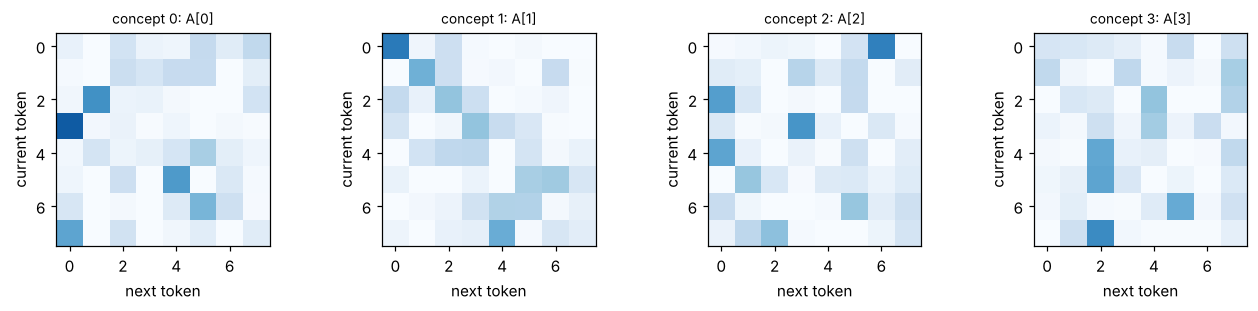

concept 0: 4 6 5 2 7 7 0 7 0 5 6 0 0 7 0 2 7 0 7 0 2 1 5 2 7 5 6 5 4 7 0 7 0 0 5 6 6 5 4 6
concept 1: 4 3 3 5 5 5 7 4 3 4 1 4 7 4 1 1 2 3 3 4 2 0 0 0 2 3 5 6 4 1 6 4 3 0 5 5 7 6 5 5
concept 2: 1 4 0 6 5 2 5 5 7 0 6 0 2 0 3 3 6 6 7 2 0 6 7 2 3 1 5 2 1 5 6 0 5 1 5 1 5 5 7 7
concept 3: 2 1 3 2 4 2 1 7 2 1 7 2 4 2 7 2 7 2 4 2 1 3 5 2 2 4 2 4 2 4 2 4 2 7 2 4 2 2 7 2


In [1]:
import time, math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import Ridge

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

V, K, T = 8, 4, 64                                   # vocabulary size, number of concepts, sequence length
rng = np.random.default_rng(0)
A = rng.dirichlet(0.3 * np.ones(V), size=(K, V))     # A[k, a, b] = p(next token b | current token a, concept k)
LOG_PRIOR = np.log(np.full(K, 1.0 / K))              # concepts are equally likely

def sample_sequences(n, A, rng):
    """Draws n sequences: concept z ~ uniform, first token ~ uniform, then the Markov chain A[z]. Returns X (n, T), z (n,)."""
    z = rng.integers(0, len(A), n)
    X = np.zeros((n, T), dtype=np.int64)
    X[:, 0] = rng.integers(0, V, n)
    for t in range(1, T):
        P = A[z, X[:, t - 1]]
        X[:, t] = (P.cumsum(1) < rng.random((n, 1))).sum(1).clip(max=V - 1)
    return X, z

X_train, z_train = sample_sequences(20000, A, rng)
X_test, z_test = sample_sequences(2000, A, rng)

fig, axes = plt.subplots(1, K, figsize=(12, 2.8))
for k in range(K):
    axes[k].imshow(A[k], cmap='Blues', vmin=0, vmax=1); axes[k].set_title(f'concept {k}: A[{k}]', fontsize=9)
    axes[k].set_xlabel('next token'); axes[k].set_ylabel('current token'); axes[k].grid(False)
plt.tight_layout(); plt.show()
for k in range(K):
    print(f'concept {k}:', ' '.join(map(str, X_test[z_test == k][0][:40])))

In [2]:
import sys, sklearn, scipy
print(f'python {sys.version.split()[0]} | torch {torch.__version__} | numpy {np.__version__} | '
      f'scikit-learn {sklearn.__version__} | device: {device.upper()}')
print('seeds: data rng 0 | EM seeds 0-4 | transformer seed 0 | random-weights control seed 1 | new concept rng 123 | diverse data rng 7')

python 3.13.18 | torch 2.15.0+cu132 | numpy 2.5.3 | scikit-learn 1.9.1 | device: CPU
seeds: data rng 0 | EM seeds 0-4 | transformer seed 0 | random-weights control seed 1 | new concept rng 123 | diverse data rng 7


---
## Part 1 — The latent-variable view (30 min)

For one sequence $\mathbf{x}=(x_1,\dots,x_T)$ the model is
$$p(\mathbf{x}, z) = p(z)\,p(x_1)\prod_{s=2}^{T}A_z[x_{s-1},x_s], \qquad p(\mathbf{x}) = \sum_{z}p(\mathbf{x},z).$$

**1.1 Posterior over the concept.** After seeing a prefix $x_{1:t}$, Bayes' rule gives
$$p(z\mid x_{1:t}) \;\propto\; p(z)\prod_{s=2}^{t}A_z[x_{s-1},x_s].$$
This is exactly the **responsibility** of a mixture model (the E-step of EM), computed for every prefix length. Implement
`concept_log_posterior` in **log-space** (products of 60 probabilities underflow quickly — compare Problem 1). Use a
running sum over $t$; no loops over sequences.

**1.2 The Bayes-optimal next-token predictor.** Averaging over the unknown concept,
$$p(x_{t+1}=v\mid x_{1:t}) = \sum_{z}p(z\mid x_{1:t})\,A_z[x_t, v].$$
No predictor that sees only $x_{1:t}$ can have a lower expected cross-entropy than this one. Implement `bayes_predictive`.

In [3]:
def concept_log_posterior(X, A, log_prior):
    """X: (n, T) tokens. Returns L of shape (n, T, K): L[i, t] = log p(z | x_1..x_t) for sequence i
    (t is 0-based: L[i, 0] uses only the first token, which carries no information about z)."""
    n, T_ = X.shape
    K_ = A.shape[0]
    logA = np.log(np.maximum(A, 1e-300))                     # (K, V, V)
    step = logA[:, X[:, :-1], X[:, 1:]].transpose(1, 2, 0)   # (n, T-1, K): log A_k[x_{s-1}, x_s] for s = 2..T
    cum = np.cumsum(step, axis=1)                            # running sum over t, no loop over sequences
    L = np.concatenate([np.zeros((n, 1, K_)), cum], axis=1) + log_prior   # unnormalised log p(z, x_1..t)
    m = L.max(-1, keepdims=True)                             # log-sum-exp normalisation (stable)
    return L - (m + np.log(np.exp(L - m).sum(-1, keepdims=True)))


def bayes_predictive(X, A, log_post):
    """Returns P of shape (n, T-1, V): P[i, t] = p(x_{t+2} = v | x_1..x_{t+1}) (prediction for the next token
    after seeing the first t+1 tokens), averaging the concepts' transition rows with the posterior weights."""
    post = np.exp(log_post[:, :-1])                          # (n, T-1, K)
    rows = A[:, X[:, :-1], :].transpose(1, 2, 0, 3)          # (n, T-1, K, V): A_k[x_t, :]
    return np.einsum('ntk,ntkv->ntv', post, rows)


def per_position_ce(P, X):
    """Average cross-entropy (nats) of predicting x_{t+1} at each position t, given predictive distributions P (n, T-1, V)."""
    p_true = np.take_along_axis(P, X[:, 1:, None], axis=2)[..., 0]
    return -np.log(np.maximum(p_true, 1e-300)).mean(0)

In [4]:
# Tests
L = concept_log_posterior(X_test[:5], A, LOG_PRIOR)
assert L.shape == (5, T, K) and np.allclose(np.exp(L).sum(-1), 1)
assert np.allclose(L[:, 0], LOG_PRIOR)
x = X_test[0, :6]                                       # brute force on one short prefix
brute = np.log(0.25) + sum(np.log(A[:, x[s - 1], x[s]]) for s in range(1, 6))
brute -= np.log(np.exp(brute).sum())
assert np.allclose(L[0, 5], brute)
P = bayes_predictive(X_test[:5], A, L)
assert P.shape == (5, T - 1, V) and np.allclose(P.sum(-1), 1)
print('Part 1 functions: OK')

Part 1 functions: OK


**1.3 How fast is the concept identified?**

> **Predict first.** After how many tokens do you expect the posterior to put more than 95% of its mass on the true
> concept, for a typical sequence?

Plot, against $t$: (a) the average posterior probability of the true concept, (b) the average entropy
$H = -\sum_z p(z\mid x_{1:t})\log p(z\mid x_{1:t})$ of the posterior (in nats), over the test set.

**Prediction (1.3).** Looking at the generated transition tables, we can tell, each row is relatively "spiky" with most elements close to zero (which tracks with the behaviour of "dirichlet(0.3)"), so a single transition is quite informative about which chain produced it.

Estimating from the generated cocept values, a typical wrong concept assigns ~4-5x lower probability to an observed transition. For the posterior to put 95% on the true concept, with three wrong concepts sharing the rest, the true concept has to become about 57 times (3 × 19) more likely than each wrong one. Gaining roughly 4-5× per transition, that takes 3-4 transitions, so we expect **about 4-5 tokens for a typical sequence** (since the first token doesnt tell us anything).



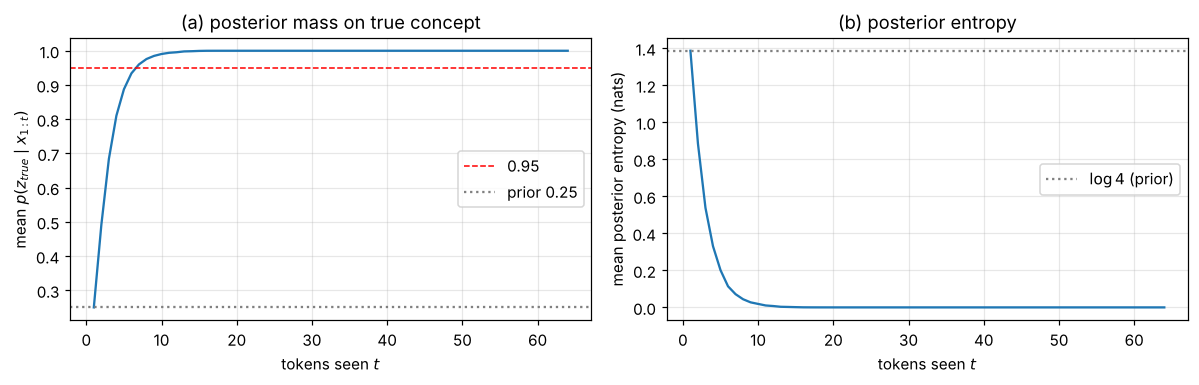

tokens needed for >95% on true concept: mean 5.0, median 5, 90th pct 7, max 16  (never within 64: 0 seqs)
average curve crosses 0.95 at t = 7
mean posterior entropy at t = 1, 5, 10, 20, 40, 64: [1.386 0.201 0.019 0.    0.    0.   ]


In [5]:
L_test = concept_log_posterior(X_test, A, LOG_PRIOR)
post_test = np.exp(L_test)                                                   # (n, T, K)
p_true_z = np.take_along_axis(post_test, z_test[:, None, None], axis=2)[..., 0]   # p(true z | x_1..t)
H_post = -(post_test * L_test).sum(-1)                                       # posterior entropy (nats)
tt = np.arange(1, T + 1)                                                     # number of tokens seen

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(tt, p_true_z.mean(0)); ax[0].axhline(0.95, color='r', ls='--', lw=1, label='0.95'); ax[0].axhline(0.25, color='gray', ls=':', label='prior 0.25')
ax[0].set(xlabel='tokens seen $t$', ylabel='mean $p(z_{true}\\mid x_{1:t})$', title='(a) posterior mass on true concept'); ax[0].legend()
ax[1].plot(tt, H_post.mean(0)); ax[1].axhline(np.log(K), color='gray', ls=':', label='$\\log 4$ (prior)')
ax[1].set(xlabel='tokens seen $t$', ylabel='mean posterior entropy (nats)', title='(b) posterior entropy'); ax[1].legend()
plt.tight_layout(); plt.show()

first95 = (p_true_z > 0.95).argmax(1) + 1          # first t with >95% on the truth (per sequence)
never = ~(p_true_z > 0.95).any(1)
print(f'tokens needed for >95% on true concept: mean {first95[~never].mean():.1f}, median {np.median(first95[~never]):.0f}, '
      f'90th pct {np.percentile(first95[~never], 90):.0f}, max {first95[~never].max()}  (never within {T}: {never.sum()} seqs)')
print('average curve crosses 0.95 at t =', int((p_true_z.mean(0) > 0.95).argmax() + 1))
print('mean posterior entropy at t = 1, 5, 10, 20, 40, 64:', np.round(H_post.mean(0)[[0, 4, 9, 19, 39, 63]], 3))

**Outcome (1.3).** As predicted: a typical sequence needs **5 tokens** (median 5, 90th percentile 7, slowest 16). A few sequences take noticeably longer (presumably those that start in less informative rows), which pulls the *average* curve's crossing of 0.95 out to $t=7$. The mean posterior entropy falls from $\log 4 \approx 1.39$ to 0.20 after 5 tokens.

---
## Part 2 — Learn the mixture from unlabelled text with EM (45 min)

So far we *knew* the transition matrices. In practice we only have text. The concept of each training sequence is a
latent variable, so the parameters $\theta=\{\pi_k, \mathbf{A}_k\}$ can be estimated by **EM** (Lecture 18), exactly as for a GMM.
Treat the first token as uniform and fixed; it carries no information.

**2.1 Sufficient statistics.** A sequence enters the likelihood only through its **transition counts**
$c_n[a,b]$ = number of times token $a$ is followed by token $b$ in sequence $n$:
$\log p(\mathbf{x}_n\mid z=k) = \text{const} + \sum_{a,b}c_n[a,b]\log A_k[a,b]$. Implement `transition_counts`.

**2.2 EM.** Derive (in a markdown cell, briefly) and implement:
* **E-step:** responsibilities $r_{nk} = p(z_n=k\mid\mathbf{x}_n,\theta) \propto \pi_k\prod_{a,b}A_k[a,b]^{c_n[a,b]}$ — the same computation as
  your `concept_log_posterior` at the last position, now with the current estimates. Work in log-space.
* **M-step:** maximise the expected complete-data log-likelihood. The result is responsibility-weighted counting:
  $\pi_k = \frac1N\sum_n r_{nk}$ and $A_k[a,b] \propto \beta + \sum_n r_{nk}\,c_n[a,b]$ (normalise each row). The small $\beta=0.01$ is a
  MAP-style pseudo-count that keeps every probability positive (Lecture 12).
* Record the **mean log-likelihood per sequence** $\frac1N\sum_n\log p(\mathbf{x}_n\mid\theta)$ at every E-step.

Initialise each $\mathbf{A}_k$ with random rows drawn from `rng.dirichlet(np.ones(V))` and $\pi_k = 1/K$.

In [6]:
def transition_counts(X):
    """Returns C of shape (n, V, V) with C[i, a, b] = number of transitions a -> b in sequence i."""
    n = X.shape[0]
    C = np.zeros((n, V, V))
    rows = np.repeat(np.arange(n), X.shape[1] - 1)
    np.add.at(C, (rows, X[:, :-1].ravel(), X[:, 1:].ravel()), 1)
    return C


def em_mixture_of_chains(C, K, n_iter=50, beta=0.01, seed=0):
    """EM for a mixture of K Markov chains from transition counts C (n, V, V).
    Returns (pi (K,), A (K, V, V), history) with history[i] = mean log-likelihood per sequence at the i-th E-step
    (up to the constant from the first token)."""
    rng_em = np.random.default_rng(seed)
    pi_k = np.full(K, 1.0 / K)
    A_k = rng_em.dirichlet(np.ones(V), size=(K, V))
    history = []
    for _ in range(n_iter):
        # E-step (log-space): log p(x_n, z=k) = log pi_k + sum_ab C_n[a,b] log A_k[a,b]
        log_joint = np.log(pi_k)[None, :] + np.einsum('nab,kab->nk', C, np.log(A_k))      # (n, K)
        m = log_joint.max(1, keepdims=True)
        log_px = m[:, 0] + np.log(np.exp(log_joint - m).sum(1))                           # log p(x_n | theta)
        history.append(log_px.mean())
        r = np.exp(log_joint - log_px[:, None])                                            # responsibilities (n, K)
        # M-step: responsibility-weighted counting
        pi_k = r.mean(0)
        A_k = beta + np.einsum('nk,nab->kab', r, C)
        A_k = A_k / A_k.sum(-1, keepdims=True)
    return pi_k, A_k, history

In [7]:
# Tests
C_small = transition_counts(X_test[:3])
assert C_small.shape == (3, V, V) and np.all(C_small.sum((1, 2)) == T - 1)
assert C_small[0, X_test[0, 0], X_test[0, 1]] >= 1
pi_t, A_t, h_t = em_mixture_of_chains(transition_counts(X_train[:2000]), K, n_iter=20)
assert np.allclose(A_t.sum(-1), 1) and np.isclose(pi_t.sum(), 1)
assert np.all(np.diff(h_t) > -1e-6), 'EM decreased the log-likelihood'
print('Part 2 functions: OK')

Part 2 functions: OK


**2.3 Run EM and check what it learned.** Run EM on all of `X_train` from 5 random initialisations (`seed=0..4`), 50
iterations each, and keep the run with the highest final log-likelihood. Then:
1. Plot the log-likelihood per iteration for all 5 runs (one figure).
2. **Match components to concepts.** EM's component 0 need not be concept 0. For each learned component find the true
   concept whose transition matrix is closest (average KL over rows), and print the matching and the distances.
3. Plot the learned (matched) transition matrices next to the true ones.

> **Predict first.** Will all 5 runs reach the same final log-likelihood? Will EM number its components in the same
> order as the true concepts?

**Prediction (2.3).** In EM iteration increases the log-likelihood, so it converges to whichever peak is closest to its random starting point, not necessarily the global maximum. With 20,000 sequences the likelihood surface is smooth and the correct solution scores far above any alternative, and because the concepts are very distinct, most random starts should climb to it. So we expect **most of the 5 runs to reach the same final log-likelihood, with one or two getting stuck at a lower value**.

We do **not** expect EM to number its components in the same order as the true concepts. Swapping the labels of two components (together with their tables) gives exactly the same likelihood, so EM has no reason to prefer any ordering; the random initialisation decides it. A random ordering of 4 components matches the true one only 1 time in 4! = 24, and we expect the numbering to differ between seeds as well.

seed 0: final mean log-lik -86.3088 | smallest step +0.0e+00 | nearest concept per component [1 2 0 3] | pi = [0.249 0.249 0.254 0.248]


seed 1: final mean log-lik -86.3088 | smallest step +0.0e+00 | nearest concept per component [0 2 1 3] | pi = [0.254 0.249 0.249 0.248]


seed 2: final mean log-lik -86.3088 | smallest step +0.0e+00 | nearest concept per component [0 3 1 2] | pi = [0.254 0.248 0.249 0.249]


seed 3: final mean log-lik -94.2010 | smallest step +8.6e-06 | nearest concept per component [2 1 0 1] | pi = [0.249 0.225 0.502 0.024]


seed 4: final mean log-lik -86.3088 | smallest step +0.0e+00 | nearest concept per component [0 2 3 1] | pi = [0.254 0.249 0.248 0.249]
true model (known A, uniform pi): -86.3148
final log-liks: [-86.3088 -86.3088 -86.3088 -94.201  -86.3088] | spread max-min = 7.8922
log-likelihood never decreases in any run: True


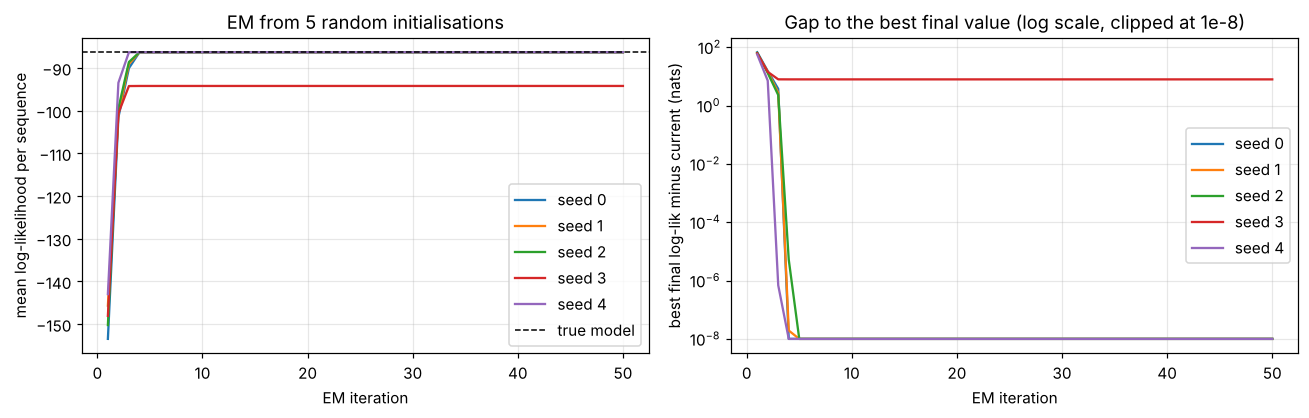

best run: seed 0
avg-row-KL(true concept k || learned component j)  [rows j = component, columns k = concept]:
[[2.5158e+00 1.0000e-04 3.7616e+00 2.5067e+00]
 [1.9728e+00 2.3742e+00 1.0000e-04 2.3965e+00]
 [1.0000e-04 3.0569e+00 2.0684e+00 1.8703e+00]
 [2.2864e+00 2.5093e+00 2.2733e+00 2.0000e-04]]
nearest concept for each component: [1 2 0 3]
one-to-one matching component -> concept: {0: 1, 1: 2, 2: 0, 3: 3} | matched distances: [9.0e-05 1.4e-04 1.1e-04 1.7e-04]
mixing weights pi (matched order): [0.254 0.249 0.249 0.248]


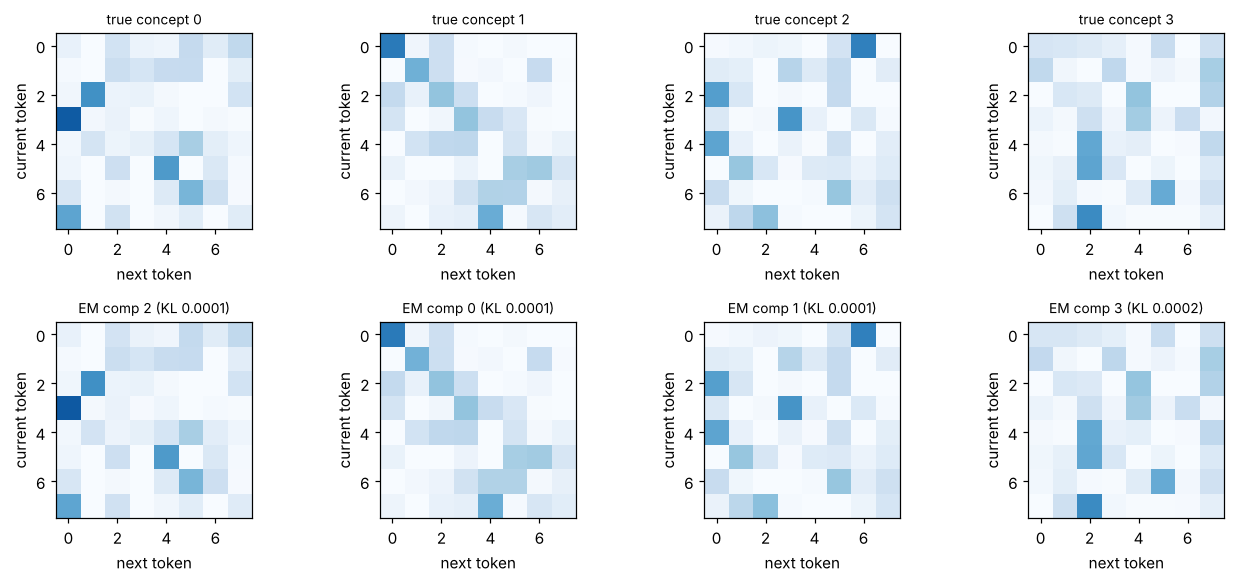

In [8]:
from scipy.optimize import linear_sum_assignment
C_train = transition_counts(X_train)

def avg_row_kl(P, Q):                       # mean over rows of KL(P[a,:] || Q[a,:])
    return (P * (np.log(np.maximum(P, 1e-300)) - np.log(np.maximum(Q, 1e-300)))).sum(-1).mean()

# reference: log-likelihood of the TRUE model on the training set, on the same scale as EM's history
lj = np.log(0.25) + np.einsum('nab,kab->nk', C_train, np.log(A)); mx = lj.max(1, keepdims=True)
ll_true = (mx[:, 0] + np.log(np.exp(lj - mx).sum(1))).mean()

runs = []
for s in range(5):
    runs.append(em_mixture_of_chains(C_train, K, n_iter=50, seed=s))
    pi_s, A_s, h_s = runs[-1]
    D_s = np.array([[avg_row_kl(A[k], A_s[j]) for k in range(K)] for j in range(K)])   # D[j,k]: component j vs concept k
    print(f'seed {s}: final mean log-lik {h_s[-1]:.4f} | smallest step {np.diff(h_s).min():+.1e} | '
          f'nearest concept per component {D_s.argmin(1)} | pi = {np.round(pi_s, 3)}')
print(f'true model (known A, uniform pi): {ll_true:.4f}')
finals = np.array([h[-1] for _, _, h in runs])
best = int(np.argmax(finals))
print('final log-liks:', np.round(finals, 4), '| spread max-min =', round(finals.max() - finals.min(), 4))
print('log-likelihood never decreases in any run:', all(np.all(np.diff(h) > -1e-9) for _, _, h in runs))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
for s, (_, _, h) in enumerate(runs):
    ax[0].plot(range(1, 51), h, label=f'seed {s}')
    ax[1].semilogy(range(1, 51), np.maximum(finals[best] - np.array(h), 1e-8), label=f'seed {s}')
ax[0].axhline(ll_true, color='k', ls='--', lw=1, label='true model')
ax[0].set(xlabel='EM iteration', ylabel='mean log-likelihood per sequence', title='EM from 5 random initialisations'); ax[0].legend()
ax[1].set(xlabel='EM iteration', ylabel='best final log-lik minus current (nats)',
          title='Gap to the best final value (log scale, clipped at 1e-8)'); ax[1].legend()
plt.tight_layout(); plt.show()

pi_em, A_em, h_em = runs[best]
print('best run: seed', best)
D = np.array([[avg_row_kl(A[k], A_em[j]) for k in range(K)] for j in range(K)])        # D[j, k]
print('avg-row-KL(true concept k || learned component j)  [rows j = component, columns k = concept]:'); print(np.round(D, 4))
print('nearest concept for each component:', D.argmin(1))
rows_j, cols_k = linear_sum_assignment(D)                                               # one-to-one matching
match = {int(j): int(k) for j, k in zip(rows_j, cols_k)}
print('one-to-one matching component -> concept:', match, '| matched distances:', np.round(D[rows_j, cols_k], 5))
inv = {k: j for j, k in match.items()}
A_em_matched = np.stack([A_em[inv[k]] for k in range(K)]); pi_em_matched = np.array([pi_em[inv[k]] for k in range(K)])
print('mixing weights pi (matched order):', np.round(pi_em_matched, 3))

fig, axes = plt.subplots(2, K, figsize=(12, 5.4))
for k in range(K):
    axes[0, k].imshow(A[k], cmap='Blues', vmin=0, vmax=1); axes[0, k].set_title(f'true concept {k}', fontsize=9)
    axes[1, k].imshow(A_em_matched[k], cmap='Blues', vmin=0, vmax=1); axes[1, k].set_title(f'EM comp {inv[k]} (KL {D[inv[k], k]:.4f})', fontsize=9)
    for r_ in range(2): axes[r_, k].grid(False); axes[r_, k].set_xlabel('next token'); axes[r_, k].set_ylabel('current token')
plt.tight_layout(); plt.show()

**Question 2.** (a) Write the expected complete-data log-likelihood and show that maximising it gives the M-step above
(a Lagrange multiplier for each row's sum-to-one constraint is enough). (b) Why does EM's numbering of the components
differ from the true one, and why does that not matter for prediction? (c) Did all initialisations agree? What does this
say about EM, and how did you deal with it?

**(a)** *E-step* (Bayes' rule, computed in log-space with log-sum-exp):

→ $\displaystyle r_{nk}=\frac{\pi_k e^{\ell_{nk}}}{\sum_j\pi_j e^{\ell_{nj}}},\qquad \ell_{nk}=\sum_{a,b}c_n[a,b]\log A_k[a,b]$

*M-step:* maximise the expected complete-data log-likelihood (plus the $\beta$ pseudo-count term):

→ $\displaystyle Q(\theta)=\sum_{n,k}r_{nk}\Big[\log\pi_k+\sum_{a,b}c_n[a,b]\log A_k[a,b]\Big]+\beta\sum_{k,a,b}\log A_k[a,b]$

→ $\displaystyle \mathcal L_{ka}=\sum_b N_{kab}\log A_k[a,b]-\lambda_{ka}\Big(\sum_b A_k[a,b]-1\Big),\quad N_{kab}=\beta+\sum_n r_{nk}c_n[a,b]$ (each row separates; one multiplier per row)

→ $\displaystyle \frac{N_{kab}}{A_k[a,b]}-\lambda_{ka}=0\;\Rightarrow\;A_k[a,b]=\frac{N_{kab}}{\lambda_{ka}}$ (set derivative to 0)

→ $\displaystyle \lambda_{ka}=\sum_b N_{kab}$ (row sums to 1, so normalise each row)

→ $\displaystyle \pi_k=\frac1N\sum_n r_{nk}$ (same method, with multiplier $\mu=N$)

Strictly, the $\beta$ term makes this MAP-EM; with $\beta=0.01$ the difference is negligible.

**(b)** As predicted, the numbering is arbitrary. The likelihood is unchanged by relabelling components, so the random initialisation picks a labelling (best run: components 0–3 are concepts 1, 2, 0, 3), and it differs between seeds (seed 1: 0, 2, 1, 3). Predictions sum over components, so the labels don't matter.

**(c)** As predicted, no. Four runs reach $-86.3088$ and match the true matrices closely (average row KL below $2\times10^{-4}$). Seed 3 stops at $-94.20$: one component ($\pi=0.50$) covers two concepts and concept 1 is split in two. EM only reaches a local maximum, so we kept the best of 5 restarts. It slightly beats the true model ($-86.3148$) by fitting training noise.

---
## Part 3 — A tiny language model (25 min)

The cell below defines a 2-layer causal transformer (Lecture 22) with about 100k parameters and trains it by
next-token prediction on `X_train` for 2000 steps. It **never sees the concept labels**. Just run it.

In [9]:
class TinyGPT(nn.Module):
    def __init__(self, d=64, layers=2, heads=4):
        super().__init__()
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(T, d)
        block = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(block, layers, enable_nested_tensor=False)
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, V)
        self.register_buffer('mask', torch.triu(torch.full((T, T), float('-inf')), 1))

    def hidden(self, x):                                  # (B, t) tokens -> (B, t, d) final hidden states
        t = x.shape[1]
        h = self.tok(x) + self.pos(torch.arange(t, device=x.device))
        return self.ln(self.blocks(h, mask=self.mask[:t, :t], is_causal=True))

    def forward(self, x):                                 # next-token logits
        return self.head(self.hidden(x))

def train_lm(X, steps=2000, batch=128, lr=3e-3, seed=0):
    torch.manual_seed(seed)
    model = TinyGPT().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    Xt = torch.from_numpy(X).to(device)
    gen = torch.Generator(device='cpu').manual_seed(seed)
    t0 = time.time()
    for step in range(steps + 1):
        xb = Xt[torch.randint(0, len(Xt), (batch,), generator=gen).to(device)]
        loss = F.cross_entropy(model(xb[:, :-1]).reshape(-1, V), xb[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 500 == 0:
            print(f'step {step:5d}  train cross-entropy {loss.item():.3f}  ({time.time() - t0:.0f}s)')
    return model.eval()

@torch.no_grad()
def lm_predictive(model, X):
    """Next-token distributions of the model, shape (n, T-1, V), as float64 numpy."""
    out = [torch.softmax(model(torch.from_numpy(X[i:i + 500, :-1]).to(device)), -1).double().cpu().numpy()
           for i in range(0, len(X), 500)]
    return np.concatenate(out)

print('parameters:', sum(p.numel() for p in TinyGPT().parameters()))
model = train_lm(X_train)

parameters: 105224


step     0  train cross-entropy 2.135  (0s)


step   500  train cross-entropy 1.400  (48s)


step  1000  train cross-entropy 1.364  (95s)


step  1500  train cross-entropy 1.375  (143s)


step  2000  train cross-entropy 1.367  (192s)


**3.1 Five predictors on the same footing.** Compute the per-position test cross-entropy of:

1. **Oracle** — *knows* the concept: predicts with $A_{z}[x_t,\cdot]$. Not achievable from the text alone; a lower reference.
2. **Bayes** — your `bayes_predictive` with the *true* $\mathbf{A}$: the best possible predictor that sees only the prefix.
3. **EM mixture** — `bayes_predictive` with *your EM estimates* $(\pi_{\text{EM}}, \mathbf{A}_{\text{EM}})$ from Part 2 (use `np.log(pi_em)`
   as the log-prior).
4. **Transformer** — `lm_predictive(model, X_test)`.
5. **Bigram, no latent variable** — a single transition matrix estimated from all training text (with add-one counts).

Plot the five curves against position, and print the average cross-entropy and the **perplexity**
$\exp(\text{cross-entropy})$ of each. Also print the number of parameters of the EM mixture and of the transformer.

> **Predict first.** Rank the five average cross-entropies. Will the transformer beat the Bayes predictor anywhere? Will
> it beat your EM mixture?

**Prediction (3.1).** Our ranking, from lowest cross-entropy (best) to highest: **Oracle < Bayes ≈ EM mixture < Transformer < Bigram.**

The oracle is told which concept wrote the sequence, so it should do best. Bayes has to figure out the concept first, so it is worse at the start, but from Part 1 it should be pretty sure after about 5–10 tokens and then match the oracle. Bayes predicts using the true probabilities, so nothing that only sees the text can do better on average, and we think the **transformer will never beat Bayes** (apart from small random dips). EM learned almost the exact tables in Part 2, so it should be basically the same as Bayes. The transformer has to learn the chains and how to tell them apart all by itself, so we think it will be close but **slightly worse than EM**. The bigram mixes all four tables into one and can't adapt to the concept, so it should be clearly the worst.

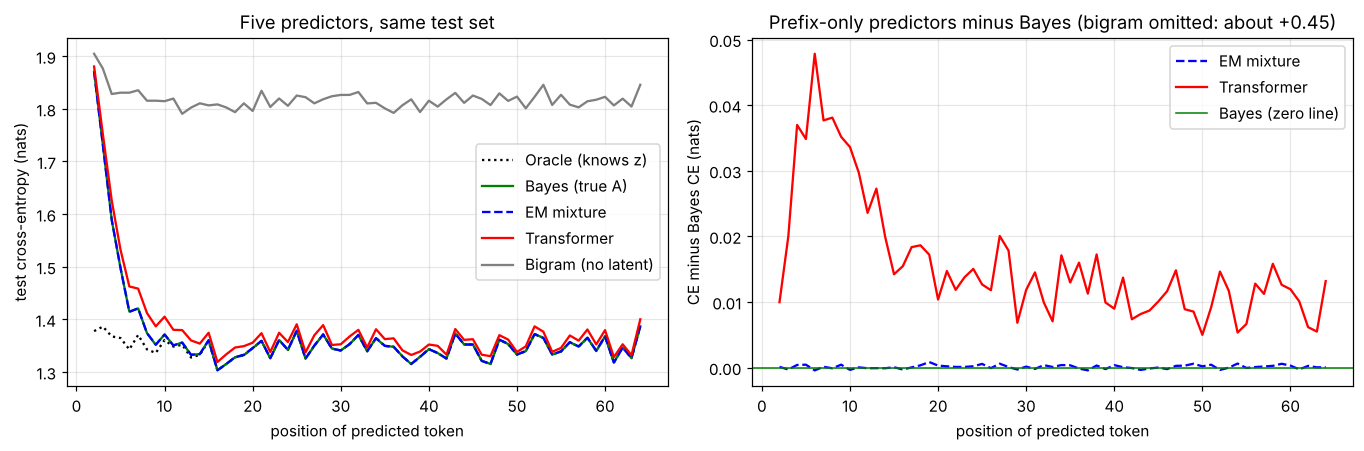

predictor               avg CE (nats)  perplexity
Oracle (knows z)               1.3469       3.846
Bayes (true A)                 1.3689       3.931
EM mixture                     1.3690       3.932
Transformer                    1.3847       3.994
Bigram (no latent)             1.8178       6.158
params: EM mixture = 227 free (K*V*(V-1) + K-1); transformer = 105224
uniform guess: CE 2.0794 perplexity 8
late positions (t>=33): {'Oracle (knows z)': 1.3453, 'Bayes (true A)': 1.3453, 'EM mixture': 1.3454, 'Transformer': 1.3562, 'Bigram (no latent)': 1.8151}
early positions (t<=8): {'Oracle (knows z)': 1.3646, 'Bayes (true A)': 1.5567, 'EM mixture': 1.5568, 'Transformer': 1.5889, 'Bigram (no latent)': 1.846}
EM mixture           per-position gap to Bayes: min -0.0004 (position 6) | positions below Bayes: 22/63 | more than 3 SE below: 0
Transformer          per-position gap to Bayes: min +0.0050 (position 50) | positions below Bayes: 0/63 | more than 3 SE below: 0
Bigram (no latent)   per-

In [10]:
Xte, zte = X_test, z_test
logpost_true = concept_log_posterior(Xte, A, LOG_PRIOR)
P = {}
P['Oracle (knows z)'] = A[zte[:, None], Xte[:, :-1]]                                        # (n, T-1, V)
P['Bayes (true A)'] = bayes_predictive(Xte, A, logpost_true)
P['EM mixture'] = bayes_predictive(Xte, A_em, concept_log_posterior(Xte, A_em, np.log(pi_em)))
P['Transformer'] = lm_predictive(model, Xte)
cnt = C_train.sum(0) + 1.0
Bi = cnt / cnt.sum(1, keepdims=True)                                                          # single bigram, add-one counts
P['Bigram (no latent)'] = Bi[Xte[:, :-1]]
ce = {name: per_position_ce(p, Xte) for name, p in P.items()}
pos = np.arange(2, T + 1)                         # position of the predicted token; prediction uses the first pos-1 tokens

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
sty = {'Oracle (knows z)': 'k:', 'Bayes (true A)': 'g-', 'EM mixture': 'b--', 'Transformer': 'r-', 'Bigram (no latent)': 'gray'}
for name, c in ce.items(): ax[0].plot(pos, c, sty[name], label=name)
ax[0].set(xlabel='position of predicted token', ylabel='test cross-entropy (nats)', title='Five predictors, same test set'); ax[0].legend()
for name in ['EM mixture', 'Transformer']: ax[1].plot(pos, ce[name] - ce['Bayes (true A)'], sty[name], label=name)
ax[1].axhline(0, color='g', lw=1, label='Bayes (zero line)')
ax[1].set(xlabel='position of predicted token', ylabel='CE minus Bayes CE (nats)',
          title='Prefix-only predictors minus Bayes (bigram omitted: about +0.45)'); ax[1].legend()
plt.tight_layout(); plt.show()

n_tf = sum(p.numel() for p in model.parameters()); n_em = K * V * (V - 1) + (K - 1)
print(f'{"predictor":22s} {"avg CE (nats)":>14s} {"perplexity":>11s}')
for name, c in ce.items(): print(f'{name:22s} {c.mean():14.4f} {np.exp(c.mean()):11.3f}')
print(f'params: EM mixture = {n_em} free (K*V*(V-1) + K-1); transformer = {n_tf}')
print('uniform guess: CE', round(np.log(V), 4), 'perplexity', V)
print('late positions (t>=33):', {k: round(float(v[32:].mean()), 4) for k, v in ce.items()})
print('early positions (t<=8):', {k: round(float(v[:7].mean()), 4) for k, v in ce.items()})

# Does any prefix-only predictor beat Bayes at some position? Paired per-sequence loss differences with standard errors.
def logq_true(Pq): return np.log(np.maximum(np.take_along_axis(Pq, Xte[:, 1:, None], 2)[..., 0], 1e-300))
gap_se = {}
for name in ['EM mixture', 'Transformer', 'Bigram (no latent)']:
    d = logq_true(P['Bayes (true A)']) - logq_true(P[name])                  # (n, T-1): loss of q minus loss of Bayes
    g, se = d.mean(0), d.std(0, ddof=1) / np.sqrt(len(Xte)); gap_se[name] = (g, se)
    print(f'{name:20s} per-position gap to Bayes: min {g.min():+.4f} (position {pos[g.argmin()]}) | '
          f'positions below Bayes: {(g < 0).sum()}/{T - 1} | more than 3 SE below: {(g < -3 * se).sum()}')
# decomposition check for Q3(a): CE_q - CE_Bayes = E KL(Bayes || q)
def _mean_kl(Pb, Q): return (Pb * (np.log(np.maximum(Pb, 1e-300)) - np.log(np.maximum(Q, 1e-300)))).sum(-1).mean()
for name in ['EM mixture', 'Transformer', 'Bigram (no latent)']:
    print(f'{name:20s} CE gap to Bayes = {ce[name].mean() - ce["Bayes (true A)"].mean():+.5f} | mean KL(Bayes||q) = {_mean_kl(P["Bayes (true A)"], P[name]):+.5f}')

**Question 3.** (a) Show that for any predictor $q$, its expected cross-entropy at position $t$ equals the Bayes
predictor's cross-entropy plus $\mathbb{E}\big[\mathrm{KL}\big(p_{\text{Bayes}}(\cdot\mid x_{1:t})\,\|\,q(\cdot\mid x_{1:t})\big)\big]$. *Hint:* given the prefix, the next token is
distributed as $p_{\text{Bayes}}$, so the expected loss is $\sum_v p_{\text{Bayes}}(v)\,(-\log q(v))$; add and subtract $\sum_v p_{\text{Bayes}}(v)\log p_{\text{Bayes}}(v)$.
Why can no model trained on this text beat the Bayes curve (up to sampling noise)? (b) Why is the oracle *lower* than
Bayes early on but equal later? (c) What does the gap between the bigram curve and the others tell you about the value
of a latent variable? (d) Compare the EM mixture and the transformer: which is closer to Bayes, and with how many
parameters? Why is this comparison "unfair" in the EM model's favour?

**(a)** Given the prefix, the next token really follows $p_B=p_{\text{Bayes}}(\cdot\mid x_{1:t})$, so for any predictor $q$:

→ $\displaystyle \mathbb E[-\log q(x_{t+1})\mid x_{1:t}]=\sum_v p_B(v)\big(-\log q(v)\big)$ (the next token is distributed as $p_B$)

→ $\displaystyle =-\sum_v p_B(v)\log p_B(v)+\sum_v p_B(v)\log\frac{p_B(v)}{q(v)}$ (add and subtract $\sum_v p_B\log p_B$)

→ $\displaystyle =\text{CE}_{\text{Bayes}}+\mathrm{KL}(p_B\,\|\,q)$ (first term is Bayes's own loss, second is the KL)

→ $\displaystyle \text{CE}_q=\text{CE}_{\text{Bayes}}+\mathbb E\big[\mathrm{KL}(p_B\,\|\,q)\big]\ge\text{CE}_{\text{Bayes}}$ (average over prefixes; KL is never negative)

So no model that only sees the text can beat Bayes on average, and a curve dipping below Bayes can only be test-set noise. Our numbers check this: the transformer is 0.0158 above Bayes and its average KL is 0.0150; for the bigram it's 0.449 vs 0.450 (they differ slightly because cross-entropy is measured on the actual sampled tokens). **Result vs prediction:** the ranking came out as we predicted: Oracle 1.347 < Bayes 1.369 ≈ EM 1.369 < Transformer 1.385 < Bigram 1.818 (perplexity 3.85, 3.93, 3.93, 3.99, 6.16). The transformer is above Bayes at all 63 positions. EM dips just below Bayes at 22 positions, but by at most 0.0004 and never by more than 3 standard errors, so that's just noise.

**(b)** The oracle is told the concept; Bayes has to work it out. At the start Bayes isn't sure yet, so the oracle wins (positions ≤ 8: 1.365 vs 1.557). After about 15 tokens Bayes is certain, and both give 1.3453 from position 33 on. The gap is how much Bayes still doesn't know about the concept.

**(c)** The bigram is on average 0.45 worse per token than Bayes (perplexity 6.16 vs 3.93). The gap is small at the first positions, where Bayes doesn't know the concept yet either, and grows to about 0.47 once it does, never closing. 
This gap is the value of the latent variable: knowing which chain is writing lets the model use its sharp table instead of one blurry average, cutting the effective choice from about 6 tokens to 4. 

**(d)** EM is much closer to Bayes (0.0001 vs 0.016) and uses only **227** parameters, against **105,224** for the transformer. The comparison is unfair because we gave EM the exact right model (4 Markov chains) and Bayes' rule for free; the transformer had to figure out both on its own from next-token prediction, in only 2000 training steps.

---
## Part 4 — In-context learning is posterior inference (20 min)

The transformer's cross-entropy *falls* along the sequence — it gets better at predicting this particular sequence as
it reads it, with fixed weights. That is in-context learning. If the transformer is doing what the Bayes predictor does,
its predictive distributions should match $p_{\text{Bayes}}$ **position by position**, not just on average.

Compute $\mathrm{KL}\big(p_{\text{Bayes}}\,\|\,p_{\text{transformer}}\big)$ at each position (average over test sequences) and plot it next to the
posterior entropy from Part 1.3. Also compute the KL of the bigram model, for scale.

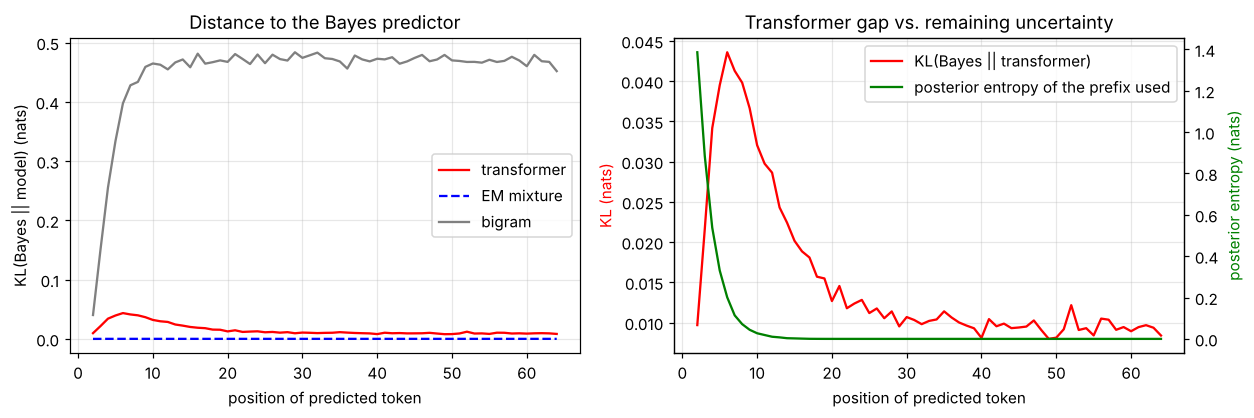

transformer KL at positions 2..8      : [0.0097 0.0216 0.0342 0.0395 0.0436 0.0413 0.0398]
argmax of transformer KL: position 6 , value 0.0436 | posterior entropy of that prefix: 0.201
mean KL early (pos 2-10) / mid (11-30) / late (31-64): [0.0331 0.0161 0.0096]
bigram KL early / late: [0.3292 0.4705]
smallest KL value (must be >= 0): 3.16e-05
corr(KL_transformer, posterior entropy): 0.226


In [11]:
def kl_per_position(P, Q):
    return (P * (np.log(np.maximum(P, 1e-300)) - np.log(np.maximum(Q, 1e-300)))).sum(-1).mean(0)

kl_tf = kl_per_position(P['Bayes (true A)'], P['Transformer'])
kl_bi = kl_per_position(P['Bayes (true A)'], P['Bigram (no latent)'])
kl_em = kl_per_position(P['Bayes (true A)'], P['EM mixture'])
H_prefix = H_post.mean(0)[:-1]                    # entropy of the prefix each prediction conditions on (length pos-1)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax[0].plot(pos, kl_tf, 'r-', label='transformer'); ax[0].plot(pos, kl_em, 'b--', label='EM mixture'); ax[0].plot(pos, kl_bi, 'gray', label='bigram')
ax[0].set(xlabel='position of predicted token', ylabel='KL(Bayes || model) (nats)', title='Distance to the Bayes predictor'); ax[0].legend()
l1, = ax[1].plot(pos, kl_tf, 'r-', label='KL(Bayes || transformer)'); ax[1].set_ylabel('KL (nats)', color='r'); ax[1].set_xlabel('position of predicted token')
ax2 = ax[1].twinx(); l2, = ax2.plot(pos, H_prefix, 'g-', label='posterior entropy of the prefix used')
ax2.set_ylabel('posterior entropy (nats)', color='g'); ax2.grid(False)
ax[1].legend(handles=[l1, l2], loc='upper right'); ax[1].set_title('Transformer gap vs. remaining uncertainty')
plt.tight_layout(); plt.show()
print('transformer KL at positions 2..8      :', np.round(kl_tf[:7], 4))
print('argmax of transformer KL: position', pos[kl_tf.argmax()], ', value', round(float(kl_tf.max()), 4),
      '| posterior entropy of that prefix:', round(float(H_prefix[kl_tf.argmax()]), 3))
print('mean KL early (pos 2-10) / mid (11-30) / late (31-64):', np.round([kl_tf[:9].mean(), kl_tf[9:29].mean(), kl_tf[29:].mean()], 4))
print('bigram KL early / late:', np.round([kl_bi[:9].mean(), kl_bi[29:].mean()], 4))
print('smallest KL value (must be >= 0):', f'{min(kl_tf.min(), kl_bi.min(), kl_em.min()):.2e}')
print('corr(KL_transformer, posterior entropy):', round(float(np.corrcoef(kl_tf, H_prefix)[0, 1]), 3))

**Question 4.** (a) Is the transformer close to the Bayes predictor at every position? Where is the gap largest, and
why might that be (compare with the posterior entropy)? (b) In two or three sentences, explain in-context learning in
this world in the language of latent variable models. What plays the role of "the prompt", and what is being
"learned" in context?

**(a)** Mostly yes: the transformer's KL to Bayes is at most 0.044 everywhere, against 0.33–0.47 for the bigram. But the gap peaks at position 6 (posterior entropy already down to 0.20), not at position 2 where uncertainty is highest. At position 2, Bayes just averages the four tables, and once the posterior is sure it uses one table, both are easy. In between, the network must weigh the concepts by exactly how much evidence each has, which is the hardest part. The leftover gap of about 0.01 later on is likely due to limited size and training.

**(b)** In latent-variable terms, the concept $z$ is the latent variable, the prompt is the observed prefix $x_{1:t}$, and training has fixed the generative model in the weights, that is the prior $p(z)$ and the likelihood of each chain $A_z$. In-context learning is Bayesian inference of $z$, that is each new token updates the posterior $p(z\mid x_{1:t})$ (the same computation as the E-step), and the prediction is the posterior predictive $\sum_z p(z\mid x_{1:t})A_z[x_t,\cdot]$. So nothing about the chains is learned in context, only which chain is writing.

---
## Part 5 — Look inside: is the posterior in the hidden state? (20 min)

If the transformer computes $p(z\mid x_{1:t})$, the posterior should be **readable** from its hidden state at position $t$.
A **linear probe** is just a linear regression trained to predict a quantity of interest from a network's hidden vectors.
Fit one with ridge regression (`sklearn.linear_model.Ridge(alpha=1.0)`, Lecture 7) from the final hidden state
(`model.hidden`, shape $(n, T, 64)$) to the 4-dimensional posterior vector, using hidden states of 1500 test sequences for
fitting and the remaining 500 for evaluation. Report $R^2$ (see the background box) on the held-out sequences for:

1. the trained transformer;
2. the same architecture with **random weights** (`torch.manual_seed(1); TinyGPT()`), as a control;
3. the trained transformer's **input embeddings only** (`model.tok(x) + model.pos(...)`), as a second control.

> **Predict first.** Which of the three will give a high $R^2$?

**Prediction (5).** Only the **trained transformer** should give a high $R^2$. From Part 4 its predictions are almost the same as Bayes, which mixes the four tables using the posterior, so it must keep track of which concept is writing somewhere in its hidden state. We expect a high but not perfect $R^2$ (**about 0.7–0.95**), because the posterior is a non-linear function of the evidence and the probe is only linear.

For the **random-weights** model we expect a **low** $R^2$. it was never trained, but its random attention still averages over the earlier tokens, giving a rough summary of which tokens have appeared, and since concepts use tokens at different rates, this should carry a little information about the concept. 

For the **input embeddings only** we expect **about zero**, they only contain the current token and its position, with no information about the earlier tokens, and one token on its own says very little about which concept produced it.

probe input                           R2 (all pos)  R2 (pos>=10)
trained transformer (final hidden)          0.8119        0.8383
random-weights transformer                  0.2532        0.2991
trained input embeddings only               0.0744        0.0756


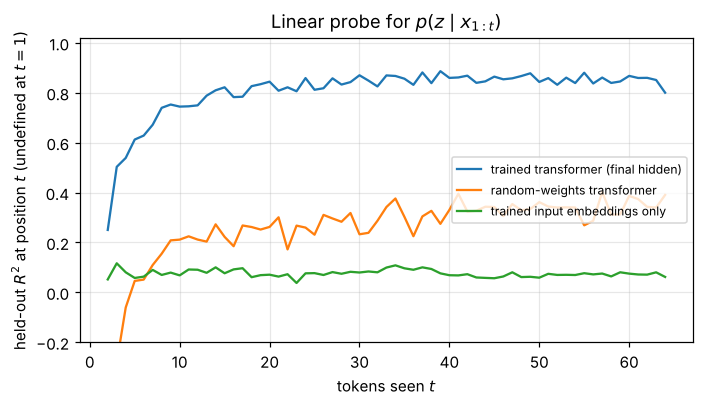

In [12]:
@torch.no_grad()
def hidden_states(model, X, embeddings_only=False):
    x = torch.from_numpy(X).to(device)
    if embeddings_only:
        h = model.tok(x) + model.pos(torch.arange(X.shape[1], device=device))
    else:
        h = model.hidden(x)
    return h.cpu().numpy()

def r2_score_pooled(Y, Yhat):
    den = ((Y - Y.mean(0)) ** 2).sum()
    return np.nan if den == 0 else 1 - ((Y - Yhat) ** 2).sum() / den   # position 1: posterior is constant, R^2 undefined

torch.manual_seed(1); model_rand = TinyGPT().to(device).eval()
Y_all = post_test                                            # (2000, T, K): true posterior at every position
n_fit = 1500
def probe(H):
    d = H.shape[-1]
    ridge = Ridge(alpha=1.0).fit(H[:n_fit].reshape(-1, d), Y_all[:n_fit].reshape(-1, K))
    Yh = ridge.predict(H[n_fit:].reshape(-1, d)).reshape(-1, T, K)
    Ye = Y_all[n_fit:]
    r2_all = r2_score_pooled(Ye.reshape(-1, K), Yh.reshape(-1, K))
    r2_late = r2_score_pooled(Ye[:, 9:].reshape(-1, K), Yh[:, 9:].reshape(-1, K))
    r2_pos = np.array([r2_score_pooled(Ye[:, t], Yh[:, t]) for t in range(T)])
    return r2_all, r2_late, r2_pos

probes = {
    'trained transformer (final hidden)': probe(hidden_states(model, X_test)),
    'random-weights transformer': probe(hidden_states(model_rand, X_test)),
    'trained input embeddings only': probe(hidden_states(model, X_test, embeddings_only=True)),
}
print(f'{"probe input":36s} {"R2 (all pos)":>13s} {"R2 (pos>=10)":>13s}')
for k, (a, b, _) in probes.items(): print(f'{k:36s} {a:13.4f} {b:13.4f}')
plt.figure(figsize=(6.5, 3.8))
for k, (_, _, rp) in probes.items(): plt.plot(np.arange(1, T + 1), rp, label=k)
plt.xlabel('tokens seen $t$'); plt.ylabel('held-out $R^2$ at position $t$ (undefined at $t=1$)'); plt.ylim(-0.2, 1.02); plt.title('Linear probe for $p(z\\mid x_{1:t})$'); plt.legend(fontsize=8, loc='center right'); plt.tight_layout(); plt.show()

**Question 5.** What do the three numbers show? Why is the "input embeddings only" control important? A high probe
$R^2$ shows that the information is *linearly present*; does it prove the network *uses* it to predict? What experiment
would test that?

As predicted, the held-out $R^2$ is **0.81** for the trained transformer (0.84 after the first 10 tokens), **0.25** for random weights and **0.07** for the input embeddings. So the posterior can be read off the trained model's hidden state quite well, and most of that comes from training, the untrained network only gets 0.25, from its random attention summarising which tokens have appeared. The embeddings-only control matters because it rules out the probe just reading the current token, with no access to earlier tokens it gets almost nothing, so the concept information must be built by the layers that look back over the prefix. $R^2$ stays below 1 because the posterior is a non-linear function of the evidence and the probe is linear.

A high $R^2$ only shows that the information is **present**, not that the network **uses** it. To test use, we would edit the hidden state along the probe's directions so that it reads as a different concept, and check that the output moves towards that concept's table, as Bayes would. Or we would remove the probe directions from the hidden state and check that the predictions get worse (KL to Bayes goes up), while removing random directions of the same size does not.

---
## Part 6 — Limits, and what changes with more diverse pretraining (25 min)

**6.1 A concept the model has never seen.** Draw a new transition matrix `A_new` the same way, generate 1000 sequences
from it, and compare the per-position cross-entropy of: the oracle (knows `A_new`), the Bayes predictor **over the 4
training concepts**, the transformer, and a simple **in-context counting** predictor that estimates the transition matrix
from the prefix itself.

The counting predictor is itself Bayesian — it is the Beta–Bernoulli posterior predictive of Lecture 12, extended to
$V$ outcomes (see the background box). If each row of the transition matrix has a Dirichlet$(\alpha,\dots,\alpha)$ prior, the
posterior predictive after seeing counts $c_{ab}$ in the prefix is
$$p(x_{t+1}=b\mid x_t=a, x_{1:t}) = \frac{c_{ab}+\alpha}{\sum_{b'}c_{ab'}+V\alpha}.$$
Implement it with $\alpha=0.3$ (the value used to generate the chains).

> **Predict first.** On the new concept, will the transformer behave like the Bayes predictor over the 4 training
> concepts, or like the in-context counting predictor?

**Prediction (6.1).** We expect the transformer to behave **somewhere in between** the two, but closer to the Bayes predictor over the 4 training concepts. It was only trained on text from the four known chains, and Parts 3–4 showed it acts almost exactly like Bayes over those four, so on a new chain it will mostly try to match the closest old chain. Recognising one of four known chains was the best strategy for its training data, so there was no strong reason for it to learn to count. However, attention can look back at earlier places where the current token appeared and see what came next, which is close to counting, so we think it may pick up a bit of the new table from the sequence. So we expect its cross-entropy to **improve a little** along the sequence, but stay well above the in-context counting predictor, which learns the new table properly from the counts and keeps getting better.

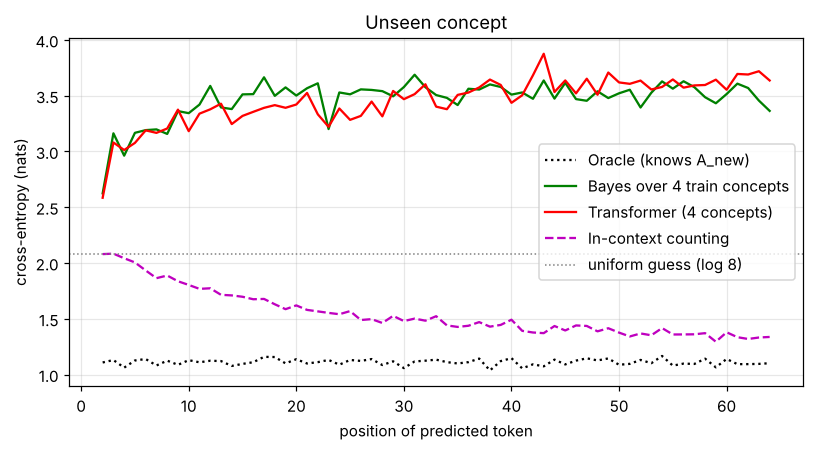

predictor                        avg CE  CE t>=33
Oracle (knows A_new)             1.1104    1.1075
Bayes over 4 train concepts      3.4649    3.5219
Transformer (4 concepts)         3.4526    3.6003
In-context counting              1.5433    1.3897
uniform guess CE: 2.0794
KL(Bayes4 || transformer) on new concept, avg: 0.6111
KL(counting || transformer) on new concept, avg: 1.5873


In [13]:
def dirichlet_count_predictive(X, alpha=0.3):
    """Returns P (n, T-1, V): P[i, t] = posterior predictive for the token after x_1..x_{t+1}, from transition counts
    within sequence i only."""
    n, T_ = X.shape
    idx = np.arange(n)
    Cc = np.zeros((n, V, V))                              # running transition counts of each prefix
    P = np.zeros((n, T_ - 1, V))
    for t in range(T_ - 1):                               # vectorised over sequences; loop over positions only
        row = Cc[idx, X[:, t], :]                         # counts c[a, :] for the current token a = x_{t+1}
        P[:, t] = (row + alpha) / (row.sum(1, keepdims=True) + V * alpha)
        Cc[idx, X[:, t], X[:, t + 1]] += 1                # now reveal the transition x_{t+1} -> x_{t+2}
    return P

rng_new = np.random.default_rng(123)
A_new = rng_new.dirichlet(0.3 * np.ones(V), size=(1, V))
X_new, _ = sample_sequences(1000, A_new, rng_new)

assert np.allclose(dirichlet_count_predictive(X_new[:3]).sum(-1), 1)
P_new = {}
P_new['Oracle (knows A_new)'] = A_new[0][X_new[:, :-1]]
P_new['Bayes over 4 train concepts'] = bayes_predictive(X_new, A, concept_log_posterior(X_new, A, LOG_PRIOR))
P_new['Transformer (4 concepts)'] = lm_predictive(model, X_new)
P_new['In-context counting'] = dirichlet_count_predictive(X_new)
ce_new = {k: per_position_ce(p, X_new) for k, p in P_new.items()}

plt.figure(figsize=(7.5, 4.2))
sty6 = {'Oracle (knows A_new)': 'k:', 'Bayes over 4 train concepts': 'g-', 'Transformer (4 concepts)': 'r-', 'In-context counting': 'm--'}
for k, c in ce_new.items(): plt.plot(np.arange(2, T + 1), c, sty6[k], label=k)
plt.axhline(np.log(V), color='gray', ls=':', lw=1, label='uniform guess (log 8)')
plt.xlabel('position of predicted token'); plt.ylabel('cross-entropy (nats)'); plt.title('Unseen concept'); plt.legend(); plt.tight_layout(); plt.show()
print(f'{"predictor":30s} {"avg CE":>8s} {"CE t>=33":>9s}')
for k, c in ce_new.items(): print(f'{k:30s} {c.mean():8.4f} {c[32:].mean():9.4f}')
print('uniform guess CE:', round(np.log(V), 4))
print('KL(Bayes4 || transformer) on new concept, avg:', round(float(kl_per_position(P_new['Bayes over 4 train concepts'], P_new['Transformer (4 concepts)']).mean()), 4))
print('KL(counting || transformer) on new concept, avg:', round(float(kl_per_position(P_new['In-context counting'], P_new['Transformer (4 concepts)']).mean()), 4))

**6.2 More diverse pretraining.** Now train the same transformer on text in which **every sequence has its own freshly
drawn chain** (unlimited concepts). Run the cell (another 2–4 minutes on CPU), then evaluate the new model on (i) the
new concept `X_new` and (ii) the original test set `X_test`, against the in-context counting predictor and the 4-concept
Bayes predictor.

In [14]:
def sample_fresh_chains(n, rng):
    As = rng.dirichlet(0.3 * np.ones(V), size=(n, V))
    X = np.zeros((n, T), dtype=np.int64); X[:, 0] = rng.integers(0, V, n)
    for t in range(1, T):
        P = As[np.arange(n), X[:, t - 1]]
        X[:, t] = (P.cumsum(1) < rng.random((n, 1))).sum(1).clip(max=V - 1)
    return X

X_diverse = sample_fresh_chains(20000, np.random.default_rng(7))
model_diverse = train_lm(X_diverse)

step     0  train cross-entropy 2.173  (0s)


step   500  train cross-entropy 1.652  (50s)


step  1000  train cross-entropy 1.642  (97s)


step  1500  train cross-entropy 1.622  (142s)


step  2000  train cross-entropy 1.611  (193s)


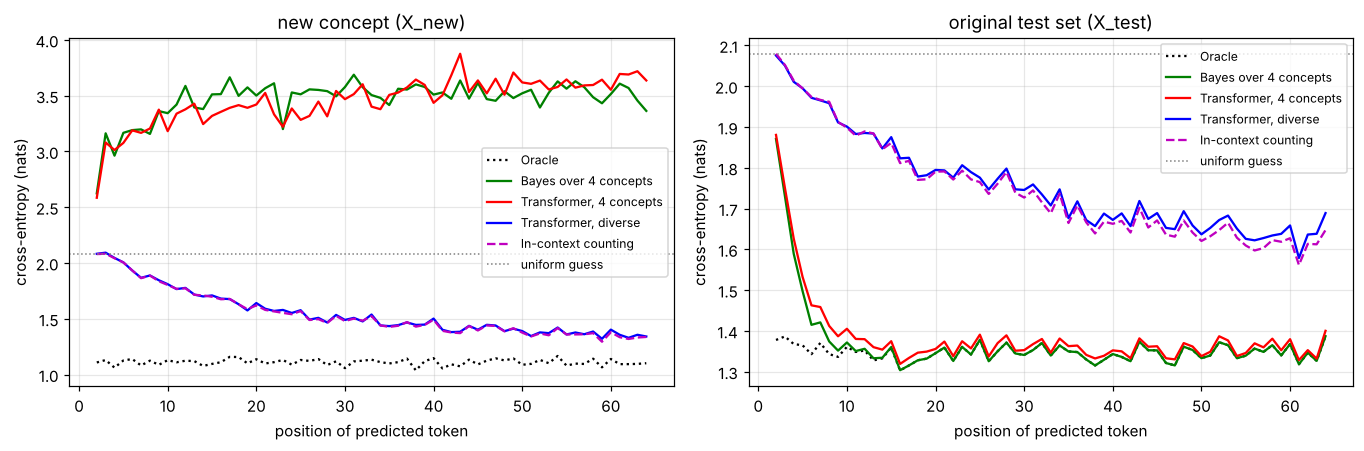

new concept (X_new)
  predictor                    avg CE  CE t>=33
  Oracle                       1.1104    1.1075
  Bayes over 4 concepts        3.4649    3.5219
  Transformer, 4 concepts      3.4526    3.6003
  Transformer, diverse         1.5503    1.3985
  In-context counting          1.5433    1.3897
original test set (X_test)
  predictor                    avg CE  CE t>=33
  Oracle                       1.3469    1.3453
  Bayes over 4 concepts        1.3689    1.3453
  Transformer, 4 concepts      1.3847    1.3562
  Transformer, diverse         1.7574    1.6629
  In-context counting          1.7448    1.6440
new concept (X_new): diverse transformer minus counting, per position: min -0.0113, mean +0.0070 | KL(counting || diverse) = 0.0122
original test set (X_test): diverse transformer minus counting, per position: min -0.0044, mean +0.0126 | KL(counting || diverse) = 0.0138
KL(Bayes4 || diverse transformer), original test: 0.3875


In [15]:
P_div_new = lm_predictive(model_diverse, X_new)
P_div_test = lm_predictive(model_diverse, X_test)
sets = {
  'new concept (X_new)': (X_new, {
      'Oracle': P_new['Oracle (knows A_new)'], 'Bayes over 4 concepts': P_new['Bayes over 4 train concepts'],
      'Transformer, 4 concepts': P_new['Transformer (4 concepts)'], 'Transformer, diverse': P_div_new,
      'In-context counting': P_new['In-context counting']}),
  'original test set (X_test)': (X_test, {
      'Oracle': P['Oracle (knows z)'], 'Bayes over 4 concepts': P['Bayes (true A)'],
      'Transformer, 4 concepts': P['Transformer'], 'Transformer, diverse': P_div_test,
      'In-context counting': dirichlet_count_predictive(X_test)}),
}
sty62 = {'Oracle': 'k:', 'Bayes over 4 concepts': 'g-', 'Transformer, 4 concepts': 'r-', 'Transformer, diverse': 'b-', 'In-context counting': 'm--'}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ce62 = {}
for ax, (title, (Xs, preds)) in zip(axes, sets.items()):
    ce62[title] = {k: per_position_ce(p, Xs) for k, p in preds.items()}
    for k, c in ce62[title].items(): ax.plot(np.arange(2, T + 1), c, sty62[k], label=k)
    ax.axhline(np.log(V), color='gray', ls=':', lw=1, label='uniform guess')
    ax.set(title=title, xlabel='position of predicted token', ylabel='cross-entropy (nats)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for title, d in ce62.items():
    print(title); print(f'  {"predictor":26s} {"avg CE":>8s} {"CE t>=33":>9s}')
    for k, c in d.items(): print(f'  {k:26s} {c.mean():8.4f} {c[32:].mean():9.4f}')
for title, (Xs, preds) in sets.items():
    g = ce62[title]['Transformer, diverse'] - ce62[title]['In-context counting']
    print(f'{title}: diverse transformer minus counting, per position: min {g.min():+.4f}, mean {g.mean():+.4f} | '
          f'KL(counting || diverse) = {kl_per_position(preds["In-context counting"], preds["Transformer, diverse"]).mean():.4f}')
print('KL(Bayes4 || diverse transformer), original test:', round(float(kl_per_position(P['Bayes (true A)'], P_div_test).mean()), 4))

**Question 6.** (a) On the new concept, which predictor does the first transformer resemble, and why can it not adapt
even after 60 tokens? (b) Which predictor does the diversely trained transformer resemble, and what does it give up on
the original 4 concepts? (c) Both transformers are (approximately) Bayes-optimal — under different priors. Explain.
(d) What does this suggest about the role of the *diversity* of an LLM's pretraining data?

**(a)** Our prediction was only partially correct, the transformer behaves like the **Bayes predictor over the 4 training concepts** (cross-entropy 3.45 vs 3.46; KL 0.61 to it vs 1.59 to counting), not in between, and it does not improve along the sequence at all. Surprisingly, both are worse than a uniform guess (2.08), they confidently commit to the closest wrong chain. Training never rewarded learning a new table, so it can only pick among the 4 it knows, while counting keeps improving (1.54 average, oracle 1.11).

**(b)** The diversely trained model behaves like the **counting predictor** (1.550 vs 1.543 on the new chain, KL 0.012). The price, on the original concepts it is about 0.39 worse per token than Bayes-4 (1.757 vs 1.369), because it estimates each table from counts instead of recognising a known chain.

**(c)** Next-token training pushes a model towards the Bayes predictor for its training data (Part 3a). Model 1's prior is "one of 4 chains", so its best predictor is the 4-concept Bayes mixture; model 2 sees a fresh Dirichlet(0.3) chain every time, so its best predictor is exactly the counting predictor $(c_{ab}+\alpha)/(c_a+V\alpha)$. Same model, different priors, different in-context learners.

**(d)** Pretraining data acts as the model's prior. Narrow data gives fast recognition of familiar tasks but nothing new, diverse data gives a general in-context learner, at a cost on familiar tasks.

---
### Self-checks

In [16]:
# Self-checks from the project sheet, gathered in one place
g_tf, se_tf = gap_se['Transformer']; g_bi, se_bi = gap_se['Bigram (no latent)']
all_preds = list(P.values()) + list(P_new.values()) + [P_div_new, P_div_test]
checks = {
    'posteriors sum to one (whole test set) and provided tests pass': np.allclose(post_test.sum(-1), 1),
    'every predictive distribution sums to one': all(np.allclose(p.sum(-1), 1) for p in all_preds),
    'EM log-likelihood never decreases (all 5 runs)': all(np.all(np.diff(h) > -1e-9) for _, _, h in runs),
    'transformer and bigram never more than 3 SE below Bayes at any position': bool(np.all(g_tf > -3 * se_tf) and np.all(g_bi > -3 * se_bi)),
    'all KL values non-negative': bool(min(kl_tf.min(), kl_bi.min(), kl_em.min()) >= -1e-12),
    'probe R2 on held-out sequences only (fit: test seqs 0-1499, evaluate: 1500-1999)': n_fit == 1500 and len(X_test) - n_fit == 500,
}
for k, v in checks.items(): print(f'[{"PASS" if v else "FAIL"}] {k}')
print(f'\ntorch {torch.__version__} | device: {device.upper()}')

[PASS] posteriors sum to one (whole test set) and provided tests pass
[PASS] every predictive distribution sums to one
[PASS] EM log-likelihood never decreases (all 5 runs)
[PASS] transformer and bigram never more than 3 SE below Bayes at any position
[PASS] all KL values non-negative
[PASS] probe R2 on held-out sequences only (fit: test seqs 0-1499, evaluate: 1500-1999)

torch 2.15.0+cu132 | device: CPU


---
## Reflection (answer briefly, 150–250 words in total)
1. Where in this lab did you use the E-step of a latent variable model, and what played the role of the "data point"?
2. A friend says: "In-context learning shows that LLMs learn during inference." Using your results, what would you say?
3. Name one way in which this toy world is too simple to tell us how real LLMs behave.

**Submit** this notebook, executed top to bottom, with your predictions, code, plots and answers.

*References:* S. M. Xie, A. Raghunathan, P. Liang, T. Ma, *An Explanation of In-context Learning as Implicit Bayesian
Inference*, ICLR 2022. A. Raventós, M. Paul, F. Chen, S. Ganguli, *Pretraining Task Diversity and the Emergence of
Non-Bayesian In-context Learning for Regression*, NeurIPS 2023.

**Answers to the reflection**

1. **E-step, two places.** (i) In Part 1, `concept_log_posterior` computes the posterior over the concept using the true tables; there the "data point" is a **prefix** $x_{1:t}$ of one sequence, updated each time a new token arrives (and reused for the Bayes and EM predictors in Parts 3–6). (ii) In Part 2, EM's E-step does the same calculation with the current estimated tables; there the data point is a **whole training sequence**, summarised by its transition counts. Same calculation, same latent variable: the concept $z$.

2. **"LLMs learn during inference."** Only in a narrow sense. The weights never change; what changes is a belief about a latent variable. The 4-concept transformer only recognises chains it already knows, and on a new chain it does not adapt at all (Part 6.1). The diverse model does pick up a new table from the prompt, but that is still Bayesian updating under a prior it got from pretraining. So what a model can "learn" in context is decided by its pretraining data.

3. Each sequence has one hidden concept, 8 tokens and first-order structure, so we can compute the exact posterior and the best possible predictor. Real text mixes many overlapping hidden factors with long-range structure, and its true prior is unknown, so we cannot compute the Bayes curve (Part 4) or the probe target (Part 5) for a real LLM.

---
## Use of AI tools

* **Code:** Claude (Anthropic) was used to assist in writing the code in `# YOUR CODE HERE` cells, which we further improved and corrected ourselves. It was also used in writing the analysis and plotting code.

* Claude was used to help understanding te underlying concepts (Dirichlet rows, posterior updating, odds, EM and label switching, linear probes, the counting predictor), did the arithmetic on the transition tables for 1.3, and helped phrase our predictions and written answers in clear words.

* **Checks:** the provided tests and the self-check cell all pass, every number quoted in the answers was checked against the printed output, and the notebook was re-run top to bottom with fixed seeds.